In [1]:
import pandas as pd
df = pd.read_csv('titanic.csv')

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  156 non-null    int64  
 1   Survived     156 non-null    int64  
 2   Pclass       156 non-null    int64  
 3   Name         156 non-null    object 
 4   Sex          156 non-null    object 
 5   Age          126 non-null    float64
 6   SibSp        156 non-null    int64  
 7   Parch        156 non-null    int64  
 8   Ticket       156 non-null    object 
 9   Fare         156 non-null    float64
 10  Cabin        31 non-null     object 
 11  Embarked     155 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 14.8+ KB


In [3]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,156.000000,156.000000,156.000000,126.000000,156.000000,156.000000,156.000000
mean,78.500000,0.346154,2.423077,28.141508,0.615385,0.397436,28.109587
std,45.177428,0.477275,0.795459,14.613880,1.056235,0.870146,39.401047
min,1.000000,0.000000,1.000000,0.830000,0.000000,0.000000,6.750000
25%,39.750000,0.000000,2.000000,19.000000,0.000000,0.000000,8.003150
50%,78.500000,0.000000,3.000000,26.000000,0.000000,0.000000,14.454200
75%,117.250000,1.000000,3.000000,35.000000,1.000000,0.000000,30.371850
max,156.000000,1.000000,3.000000,71.000000,5.000000,5.000000,263.000000


<Axes: xlabel='Survived', ylabel='count'>

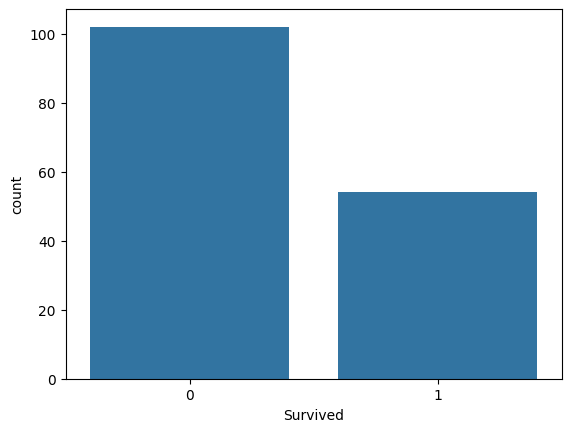

In [4]:
import seaborn as sns
sns.countplot(df, x="Survived")


In [5]:
df['Survived'].value_counts()

Survived
0    102
1     54
Name: count, dtype: int64

In [6]:
df = pd.concat([df[df['Survived'] == 1], df], ignore_index=True)
df['Survived'].value_counts()

Survived
1    108
0    102
Name: count, dtype: int64

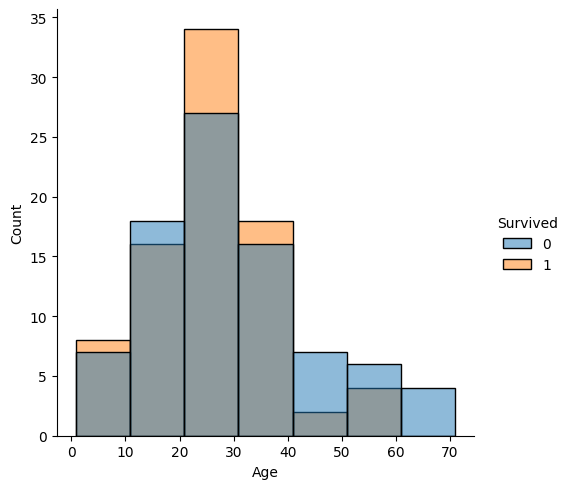

In [7]:
sns.displot(df, x='Age', binwidth=10, hue='Survived')

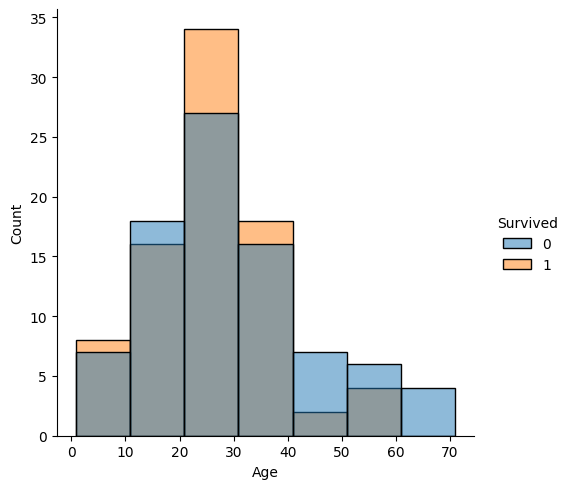

In [8]:
import seaborn as sns
sns.displot(df.dropna(subset='Age', axis=0), x='Age', binwidth=10, hue='Survived')

<Axes: xlabel='Sex', ylabel='count'>

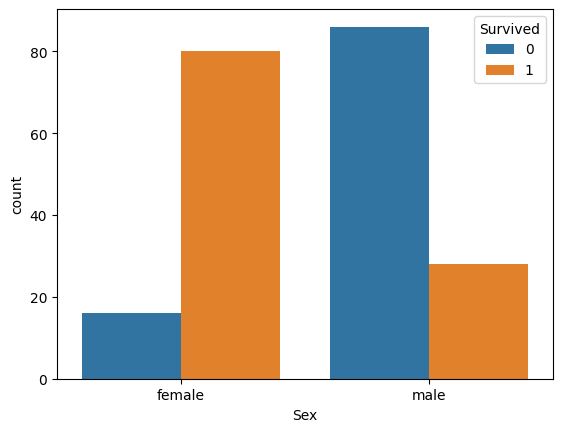

In [9]:
sns.countplot(df, x="Sex", hue='Survived')


<Axes: xlabel='Pclass', ylabel='count'>

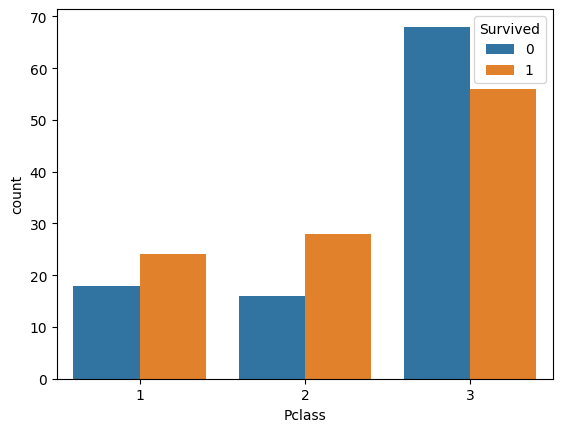

In [10]:
sns.countplot(df, x="Pclass", hue='Survived')

In [11]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

In [12]:
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()
categorical_columns

['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']

In [13]:
df = df.drop(columns=['Name', 'Ticket', 'PassengerId'])
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,1,1,female,38.0,1,0,71.2833,C85,C
1,1,3,female,26.0,0,0,7.9250,NaN,S
2,1,1,female,35.0,1,0,53.1000,C123,S
3,1,3,female,27.0,0,2,11.1333,NaN,S
4,1,2,female,14.0,1,0,30.0708,NaN,C
...,...,...,...,...,...,...,...,...,...
205,1,1,female,22.0,1,0,66.6000,C2,S
206,0,3,male,55.5,0,0,8.0500,NaN,S
207,0,3,male,40.5,0,2,14.5000,NaN,S
208,0,3,male,NaN,0,0,7.3125,NaN,S


In [14]:
categorical_columns = ['Sex', 'Cabin', 'Embarked']

In [15]:
for col in categorical_columns:
    mode = df[col].mode().iloc[0]
    print(col, mode)
    df[col] = df[col].fillna(mode)
df

Sex male
Cabin C123
Embarked S


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,1,1,female,38.0,1,0,71.2833,C85,C
1,1,3,female,26.0,0,0,7.9250,C123,S
2,1,1,female,35.0,1,0,53.1000,C123,S
3,1,3,female,27.0,0,2,11.1333,C123,S
4,1,2,female,14.0,1,0,30.0708,C123,C
...,...,...,...,...,...,...,...,...,...
205,1,1,female,22.0,1,0,66.6000,C2,S
206,0,3,male,55.5,0,0,8.0500,C123,S
207,0,3,male,40.5,0,2,14.5000,C123,S
208,0,3,male,NaN,0,0,7.3125,C123,S


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  210 non-null    int64  
 1   Pclass    210 non-null    int64  
 2   Sex       210 non-null    object 
 3   Age       167 non-null    float64
 4   SibSp     210 non-null    int64  
 5   Parch     210 non-null    int64  
 6   Fare      210 non-null    float64
 7   Cabin     210 non-null    object 
 8   Embarked  210 non-null    object 
dtypes: float64(2), int64(4), object(3)
memory usage: 14.9+ KB


In [17]:
for col in categorical_columns:
    print(col, df[col].unique(), df[col].nunique())

Sex ['female' 'male'] 2
Cabin ['C85' 'C123' 'G6' 'C103' 'D56' 'A6' 'B78' 'D33' 'C52' 'B28' 'F33'
 'C23 C25 C27' 'D10 D12' 'E101' 'F E69' 'D47' 'C2' 'E46' 'B30' 'C83'
 'F G73' 'E31' 'A5' 'D26' 'C110' 'B58 B60' 'B86' 'F2'] 28
Embarked ['C' 'S' 'Q'] 3


In [18]:
one_hot_categorical_columns = ['Sex', 'Embarked']
encoder = OneHotEncoder(sparse_output=False)
one_hot_encoded = encoder.fit_transform(df[one_hot_categorical_columns])
one_hot_encoded

array([[1., 0., 1., 0., 0.],
       [1., 0., 0., 0., 1.],
       [1., 0., 0., 0., 1.],
       ...,
       [0., 1., 0., 0., 1.],
       [0., 1., 0., 0., 1.],
       [0., 1., 1., 0., 0.]])

In [19]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,1,1,female,38.0,1,0,71.2833,C85,C
1,1,3,female,26.0,0,0,7.9250,C123,S
2,1,1,female,35.0,1,0,53.1000,C123,S
3,1,3,female,27.0,0,2,11.1333,C123,S
4,1,2,female,14.0,1,0,30.0708,C123,C
...,...,...,...,...,...,...,...,...,...
205,1,1,female,22.0,1,0,66.6000,C2,S
206,0,3,male,55.5,0,0,8.0500,C123,S
207,0,3,male,40.5,0,2,14.5000,C123,S
208,0,3,male,NaN,0,0,7.3125,C123,S


In [20]:
  ['Cabin'] = label_encoder.fit_transform(df['Cabin'])
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,1,1,female,38.0,1,0,71.2833,14,C
1,1,3,female,26.0,0,0,7.9250,9,S
2,1,1,female,35.0,1,0,53.1000,9,S
3,1,3,female,27.0,0,2,11.1333,9,S
4,1,2,female,14.0,1,0,30.0708,9,C
...,...,...,...,...,...,...,...,...,...
205,1,1,female,22.0,1,0,66.6000,10,S
206,0,3,male,55.5,0,0,8.0500,9,S
207,0,3,male,40.5,0,2,14.5000,9,S
208,0,3,male,NaN,0,0,7.3125,9,S


In [21]:
one_hot_df = pd.DataFrame(one_hot_encoded, columns=encoder.get_feature_names_out(one_hot_categorical_columns))
one_hot_df

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1.0,0.0,1.0,0.0,0.0
1,1.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...
205,1.0,0.0,0.0,0.0,1.0
206,0.0,1.0,0.0,0.0,1.0
207,0.0,1.0,0.0,0.0,1.0
208,0.0,1.0,0.0,0.0,1.0


In [22]:
df = df.drop(columns=['Sex', 'Embarked']).merge(one_hot_df, left_index=True, right_index=True)

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    210 non-null    int64  
 1   Pclass      210 non-null    int64  
 2   Age         167 non-null    float64
 3   SibSp       210 non-null    int64  
 4   Parch       210 non-null    int64  
 5   Fare        210 non-null    float64
 6   Cabin       210 non-null    int32  
 7   Sex_female  210 non-null    float64
 8   Sex_male    210 non-null    float64
 9   Embarked_C  210 non-null    float64
 10  Embarked_Q  210 non-null    float64
 11  Embarked_S  210 non-null    float64
dtypes: float64(7), int32(1), int64(4)
memory usage: 19.0 KB


In [24]:
# df = df.dropna(subset=['Age'])
df = df.dropna(subset=['Age'])

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 167 entries, 0 to 209
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    167 non-null    int64  
 1   Pclass      167 non-null    int64  
 2   Age         167 non-null    float64
 3   SibSp       167 non-null    int64  
 4   Parch       167 non-null    int64  
 5   Fare        167 non-null    float64
 6   Cabin       167 non-null    int32  
 7   Sex_female  167 non-null    float64
 8   Sex_male    167 non-null    float64
 9   Embarked_C  167 non-null    float64
 10  Embarked_Q  167 non-null    float64
 11  Embarked_S  167 non-null    float64
dtypes: float64(7), int32(1), int64(4)
memory usage: 16.3 KB


In [25]:
X, y = df.drop(columns='Survived'), df['Survived']

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [27]:

lr = LogisticRegression()

In [28]:
lr.fit(X_train, y_train)

c:\Users\hitmachut\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [29]:
y_pred = lr.predict_proba(X_test)[:, 1]
y_pred

array([0.85443325, 0.39547807, 0.77447334, 0.30755157, 0.92313553,
       0.01714797, 0.28606186, 0.86455857, 0.38828468, 0.97757544,
       0.22732862, 0.5072473 , 0.1846678 , 0.77447334, 0.26890342,
       0.86093304, 0.91110689, 0.25594462, 0.30154938, 0.2796626 ,
       0.27441472, 0.22650153, 0.55553168, 0.04792015, 0.26337594,
       0.86785395, 0.00931143, 0.84325624, 0.77447334, 0.07899324,
       0.32032599, 0.78352509, 0.91110689, 0.11308379])

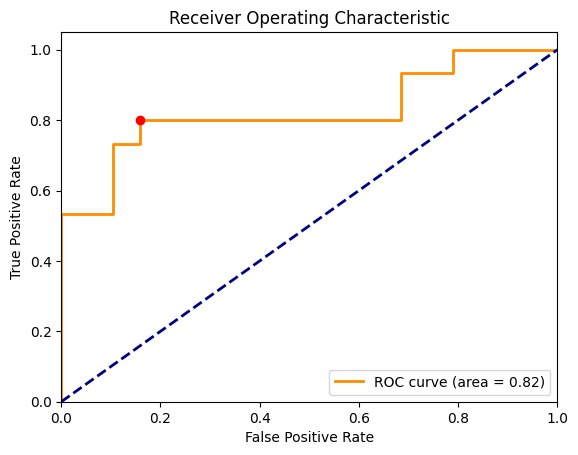

In [30]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Assuming you have:
# - y_true: True binary labels (0 or 1)
# - y_score: Predicted probabilities for the positive class

fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = auc(fpr, tpr)

# Find the index of the optimal threshold (e.g., Youden's J statistic)
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]
optimal_fpr = fpr[optimal_idx]
optimal_tpr = tpr[optimal_idx]

# Plot the ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")

# Plot the point corresponding to the optimal threshold
plt.plot(optimal_fpr, optimal_tpr, marker='o', color='red', label='Optimal Threshold')

plt.show()

In [31]:
optimal_threshold

0.5072473014151686

In [32]:
from sklearn.metrics import confusion_matrix, classification_report

In [33]:
print(classification_report(y_test, lr.predict(X_test)))

              precision    recall  f1-score   support

           0       0.84      0.84      0.84        19
           1       0.80      0.80      0.80        15

    accuracy                           0.82        34
   macro avg       0.82      0.82      0.82        34
weighted avg       0.82      0.82      0.82        34

